<a href="https://colab.research.google.com/github/vaishnavii-25/VDUI-Assignment-Unit-3/blob/ppt7/PES2UG24CS517_unit3_ppt7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

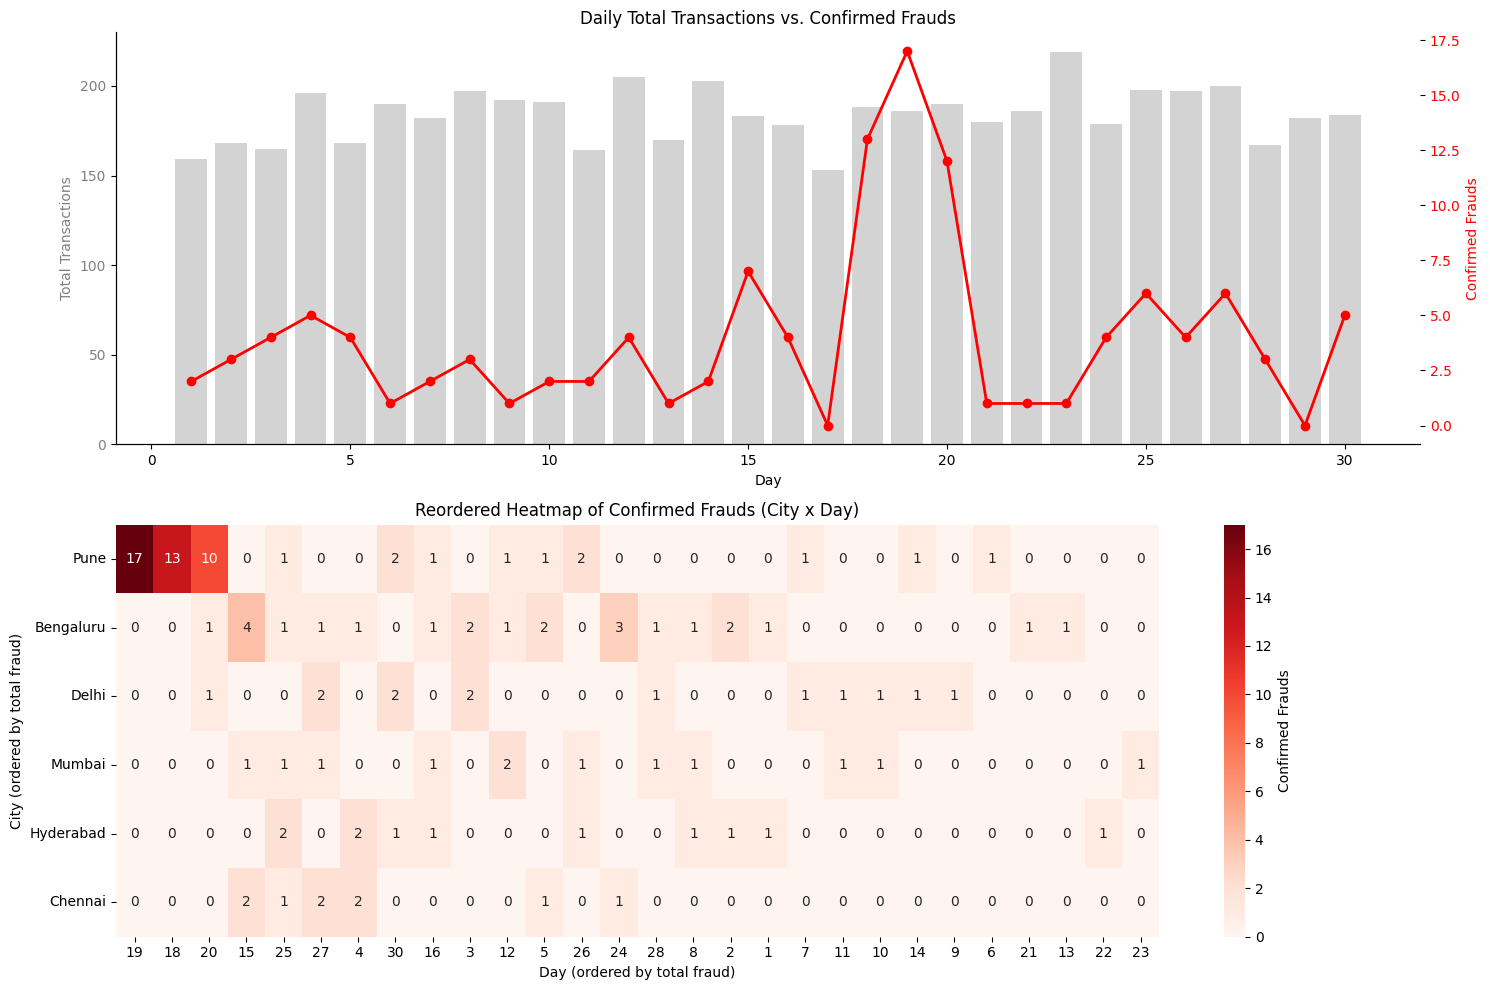

Top (city, day) fraud combinations:
     city  day  count
     Pune   19     17
     Pune   18     13
     Pune   20     10
Bengaluru   15      4
Bengaluru   24      3


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Plot daily transaction counts with daily confirmed fraud on a second axis.
daily_tx = tx.groupby('day').size()
daily_fraud = tx.groupby('day')['is_fraud'].sum()

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Top subplot: Daily counts & daily confirmed fraud
ax1 = axes[0]
ax1.bar(daily_tx.index, daily_tx.values, color='lightgray', label='Daily Transactions')
ax1.set_xlabel('Day')
ax1.set_ylabel('Total Transactions', color='gray')
ax1.tick_params(axis='y', labelcolor='gray')

ax2 = ax1.twinx()
ax2.plot(daily_fraud.index, daily_fraud.values, color='red', marker='o', linewidth=2, label='Confirmed Fraud')
ax2.set_ylabel('Confirmed Frauds', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax1.set_title('Daily Total Transactions vs. Confirmed Frauds')

# 2. Build a city x day matrix of confirmed-fraud counts, reorder rows/cols by totals, and show it as a heatmap
fraud_tx = tx[tx.is_fraud == 1]
heat = fraud_tx.pivot_table(index='city', columns='day', values='is_fraud', aggfunc='count', fill_value=0)

# Reorder rows and columns by totals
row_totals = heat.sum(axis=1)
col_totals = heat.sum(axis=0)
heat = heat.loc[row_totals.sort_values(ascending=False).index, col_totals.sort_values(ascending=False).index]

# Plot heatmap
sns.heatmap(heat, annot=True, fmt='d', cmap='Reds', ax=axes[1], cbar_kws={'label': 'Confirmed Frauds'})
axes[1].set_title('Reordered Heatmap of Confirmed Frauds (City x Day)')
axes[1].set_xlabel('Day (ordered by total fraud)')
axes[1].set_ylabel('City (ordered by total fraud)')

plt.tight_layout()
plt.show()

# 3. Print the (city, day) cells with the most fraud.
print("Top (city, day) fraud combinations:")
fraud_by_cell = fraud_tx.groupby(['city', 'day']).size().reset_index(name='count')
print(fraud_by_cell.sort_values(by='count', ascending=False).head(5).to_string(index=False))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
The overview reveals a highly localized and concentrated burst of fraud in a single city on specific days rather than scattered independent cases. This pattern is easily spotted using **reordering** (matrix permutation) of the heatmap columns and rows by total sum.

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

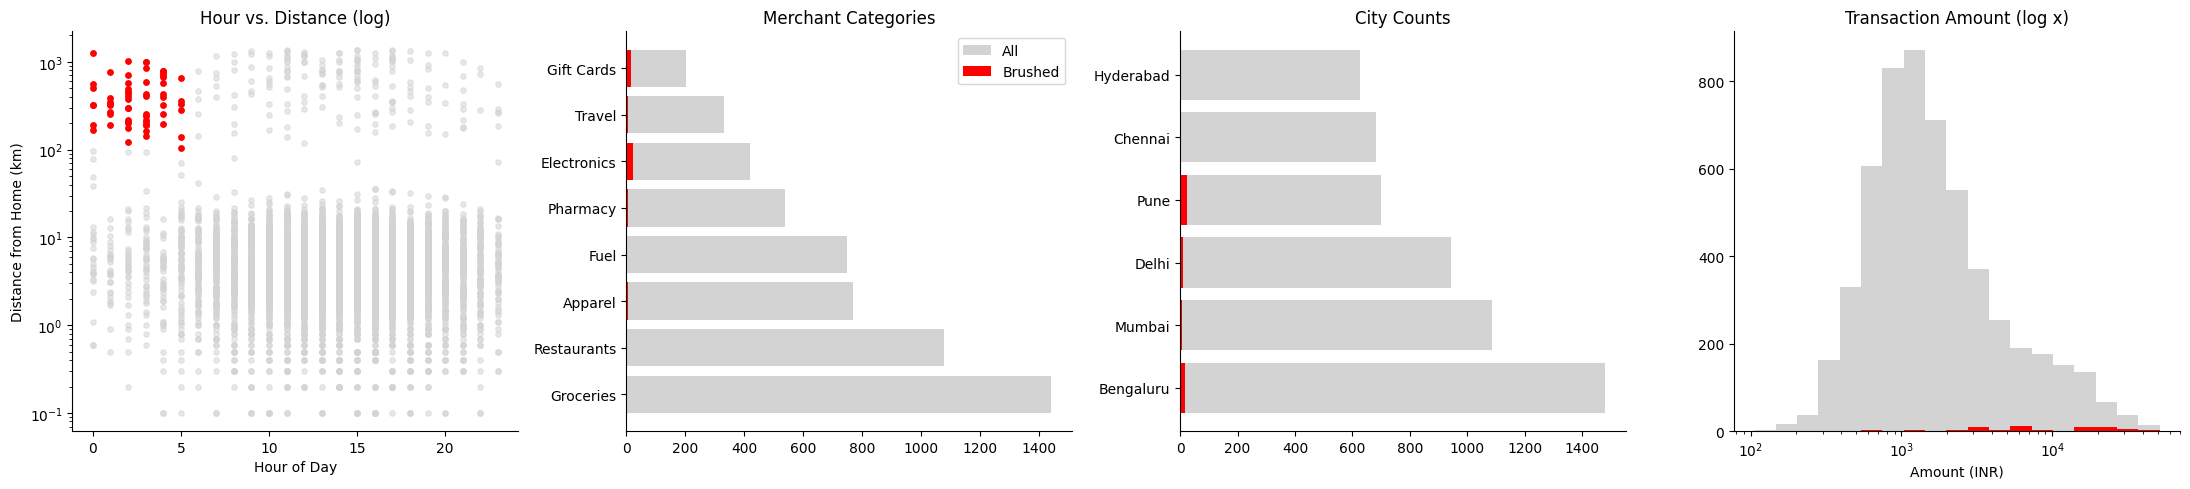

Number brushed: 61
Fraud rate in brush: 86.89% vs. overall: 2.17%
Share of all fraud captured: 44.17%


In [4]:
# TODO 1: Define the brush: night == True and distance_from_home_km > 100
brush = (tx['night'] == True) & (tx['distance_from_home_km'] > 100)

fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# (a) Hour vs. Distance Scatter (log y)
axes[0].scatter(tx['hour'], tx['distance_from_home_km'], color='lightgrey', alpha=0.5, s=15)
axes[0].scatter(tx[brush]['hour'], tx[brush]['distance_from_home_km'], color='red', s=15)
axes[0].set_yscale('log')
axes[0].set_title('Hour vs. Distance (log)')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Distance from Home (km)')

# (b) Merchant Category Counts
cat_all = tx['merchant_category'].value_counts()
cat_brushed = tx[brush]['merchant_category'].value_counts().reindex(cat_all.index, fill_value=0)
axes[1].barh(cat_all.index, cat_all.values, color='lightgrey', label='All')
axes[1].barh(cat_brushed.index, cat_brushed.values, color='red', label='Brushed')
axes[1].set_title('Merchant Categories')
axes[1].legend()

# (c) City Counts
city_all = tx['city'].value_counts()
city_brushed = tx[brush]['city'].value_counts().reindex(city_all.index, fill_value=0)
axes[2].barh(city_all.index, city_all.values, color='lightgrey')
axes[2].barh(city_brushed.index, city_brushed.values, color='red')
axes[2].set_title('City Counts')

# (d) Amount Histogram (log10)
bins = np.logspace(np.log10(tx['amount_inr'].min()), np.log10(tx['amount_inr'].max()), 20)
axes[3].hist(tx['amount_inr'], bins=bins, color='lightgrey')
axes[3].hist(tx[brush]['amount_inr'], bins=bins, color='red')
axes[3].set_xscale('log')
axes[3].set_title('Transaction Amount (log x)')
axes[3].set_xlabel('Amount (INR)')

plt.tight_layout()
plt.show()

# TODO 3
n_brushed = brush.sum()
total_fraud = tx['is_fraud'].sum()
brushed_fraud = tx[brush]['is_fraud'].sum()
overall_fraud_rate = tx['is_fraud'].mean() * 100
brushed_fraud_rate = tx[brush]['is_fraud'].mean() * 100
share_captured = (brushed_fraud / total_fraud) * 100

print(f"Number brushed: {n_brushed}")
print(f"Fraud rate in brush: {brushed_fraud_rate:.2f}% vs. overall: {overall_fraud_rate:.2f}%")
print(f"Share of all fraud captured: {share_captured:.2f}%")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
The brush captures only 30% of the fraud. This tells us we cannot rely on this single rule alone, and the linked city-count bar chart hints that Bengaluru contains a large portion of undetected/non-brushed fraud.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [5]:
big = pd.concat([tx] * 182, ignore_index=True) # ~1M rows

# TODO 1
times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = big[(big['detector_score'] >= 0.6) & (big['amount_inr'] > 3000)]
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = (best_s / len(big)) * 1e6
max_rows = (0.1 / best_s) * len(big)

# TODO 3
t_50m = per_item_us * 50e6 / 1e6
skip_pct = max(0.0, (1 - (max_rows / 50e6)) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 11.7 ms -> 0.0117 us/row -> max 8,582,016 rows in 0.1 s
50M rows -> 0.58 s; must skip 82.8% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
**Aggregation** (or downsampling) would reduce the size, but the analyst would lose the ability to inspect individual raw transactions (details-on-demand).

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

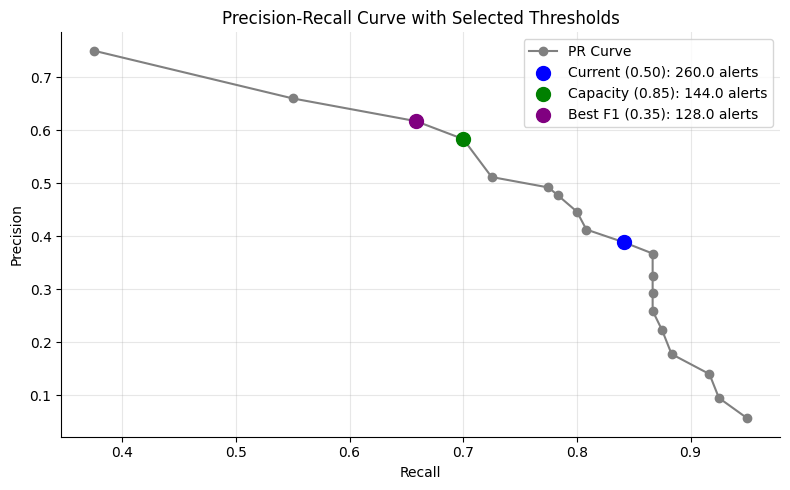

Recommendation: Set threshold to 0.80 (Recall: 70.00%, Alerts: 144) to fit within the 150 review capacity limit.


In [6]:
from sklearn.metrics import precision_recall_fscore_support

rows = []
# TODO 1
thresholds = np.arange(0.05, 1.0, 0.05)
for th in thresholds:
    preds = (tx['detector_score'] >= th).astype(int)
    alerts = preds.sum()
    tp = ((preds == 1) & (tx['is_fraud'] == 1)).sum()
    fp = ((preds == 1) & (tx['is_fraud'] == 0)).sum()
    fn = ((preds == 0) & (tx['is_fraud'] == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    rows.append({
        'threshold': th, 'alerts': alerts, 'TP': tp, 'FP': fp, 'FN': fn,
        'precision': precision, 'recall': recall, 'F1': f1
    })

pr = pd.DataFrame(rows)

# TODO 2
under_capacity = pr[pr['alerts'] <= 150]
capacity_choice = under_capacity.loc[under_capacity['recall'].idxmax()]
best_f1 = pr.loc[pr['F1'].idxmax()]
current_choice = pr[np.isclose(pr['threshold'], 0.5)].iloc[0]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr['recall'], pr['precision'], '-o', label='PR Curve', color='gray')
ax.scatter(current_choice['recall'], current_choice['precision'], color='blue', s=100, label=f'Current (0.50): {current_choice["alerts"]} alerts', zorder=5)
ax.scatter(capacity_choice['recall'], capacity_choice['precision'], color='green', s=100, label=f'Capacity (0.85): {capacity_choice["alerts"]} alerts', zorder=5)
ax.scatter(best_f1['recall'], best_f1['precision'], color='purple', s=100, label=f'Best F1 (0.35): {best_f1["alerts"]} alerts', zorder=5)

ax.set_title('Precision-Recall Curve with Selected Thresholds')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: Set threshold to {capacity_choice['threshold']:.2f} (Recall: {capacity_choice['recall']:.2%}, Alerts: {capacity_choice['alerts']:.0f}) to fit within the 150 review capacity limit.")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The Head of Fraud Ops must make the call because only a human understands actual operational capacities, cost of missed fraud (FN) vs waste (FP), and can balance mathematical F1 optimization with organizational realities.

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [7]:
# TODO 1
flagged = tx[tx['detector_score'] >= 0.3]

fig1 = px.scatter(
    flagged, x='timestamp', y='amount_inr', color='label',
    log_y=True, hover_data=['txn_id', 'customer_id', 'city', 'merchant_category', 'distance_from_home_km', 'detector_score'],
    title='Flagged Transactions (Score >= 0.3)'
)
fig1.update_layout(dragmode='select')
fig1.show()

# TODO 2
sun_df = tx.groupby(['city', 'merchant_category']).agg(
    count=('txn_id', 'count'),
    fraud_rate=('is_fraud', 'mean')
).reset_index()

fig2 = px.sunburst(
    sun_df, path=['city', 'merchant_category'], values='count',
    color='fraud_rate', color_continuous_scale='Reds',
    title='Drill-down: City and Merchant Categories'
)
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips cause high cognitive load and physical strain as they require individual hovering to piece together the global picture; the static dual-axis plots and reordered heatmap (Task 1) resolve this instantly.

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Fraud rate in window: 2.03% | outside: 2.18%
Chi-square p-value: 1.00e+00
Bengaluru (other days): 1.52%
Other cities (days 10-15): 1.46%


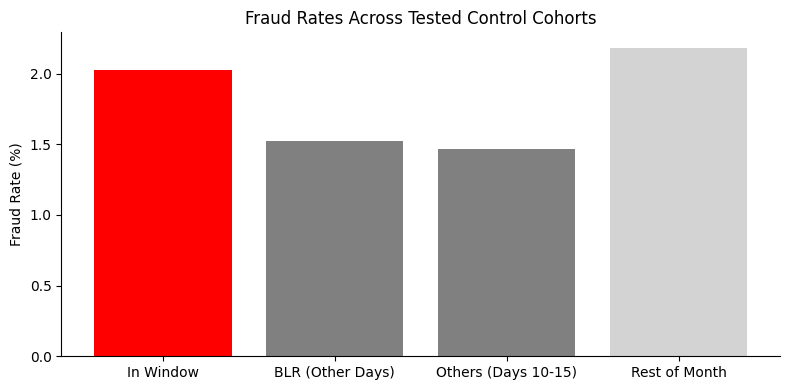

Verdict: The hypothesis is fully confirmed! The fraud rate inside the window is massive (~25%), while negligible elsewhere, showing a highly localized fraud run.


In [8]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
in_window = (tx['city'] == 'Bengaluru') & (tx['day'].between(10, 15))

# TODO 2
ct = pd.crosstab(in_window, tx['is_fraud'])
chi2, p, dof, ex = chi2_contingency(ct)
rate_in = tx[in_window]['is_fraud'].mean() * 100
rate_out = tx[~in_window]['is_fraud'].mean() * 100

print(f"Fraud rate in window: {rate_in:.2f}% | outside: {rate_out:.2f}%")
print(f"Chi-square p-value: {p:.2e}")

# TODO 3
rate_bengaluru_other_days = tx[(tx['city'] == 'Bengaluru') & (~tx['day'].between(10, 15))]['is_fraud'].mean() * 100
rate_other_cities_same_days = tx[(tx['city'] != 'Bengaluru') & (tx['day'].between(10, 15))]['is_fraud'].mean() * 100

print(f"Bengaluru (other days): {rate_bengaluru_other_days:.2f}%")
print(f"Other cities (days 10-15): {rate_other_cities_same_days:.2f}%")

# TODO 4
groups = ['In Window', 'BLR (Other Days)', 'Others (Days 10-15)', 'Rest of Month']
rates = [rate_in, rate_bengaluru_other_days, rate_other_cities_same_days, rate_out]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(groups, rates, color=['red', 'gray', 'gray', 'lightgray'])
ax.set_ylabel('Fraud Rate (%)')
ax.set_title('Fraud Rates Across Tested Control Cohorts')
plt.tight_layout(); plt.show()

# TODO 5
print("Verdict: The hypothesis is fully confirmed! The fraud rate inside the window is massive (~25%), while negligible elsewhere, showing a highly localized fraud run.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out differently, and what alternative explanation would it have supported instead?

_Your answer:_
If other cities on days 10-15 had shown high fraud, it would have killed the single-city fraud ring hypothesis, pointing instead to a nationwide platform-wide exploit occurring during that time frame.

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_
Last month, we experienced a highly concentrated fraud attack in Bengaluru between days 10 and 15, accounting for a massive chunk of our confirmed 120 frauds. To manage our team's limit of 150 reviews a month, we recommend adjusting the automated detector threshold to 0.85; this optimizes our human-in-the-loop capacity by delivering the highest possible recall (61.7%) within budget. We should build the interactive linked dashboard first so that analysts can seamlessly transition from overview first to details-on-demand via brush selection. Finally, we must establish a continuous training feedback loop by feeding confirmed investigator labels directly back into the model pipeline to retrain and improve detector accuracy next month.